# Join the Split DFs

In [1]:
import pandas as pd
join_df1 = pd.read_parquet("../prompt_engineering/output/dataset_animalia_with_prompts_1.parquet")
join_df2 = pd.read_parquet("../prompt_engineering/output/dataset_animalia_with_prompts_2.parquet")
join_df3 = pd.read_parquet("../prompt_engineering/output/dataset_animalia_with_prompts_3.parquet")

In [2]:
print("-----Split 1 df ------")
print(f"Shape: {join_df1.shape}")
print("--------------------------")
missing = join_df1.isna().sum()
print(f"Missing values:\n{missing[missing > 0]}")

-----Split 1 df ------
Shape: (8000, 38)
--------------------------
Missing values:
predator_prey_role      263
common_name             717
latitude                  6
longitude                 6
positional_accuracy    1124
class_name               13
order_name                5
family_name               4
genus_name                1
species_name            124
subspecies_name        5999
subfamily_name         7999
hybrid_name            7984
complex_name           7993
form_name              7993
subgenus_name          7986
variety_name           7995
tribe_name             8000
country                   6
state                     7
city                      6
dtype: int64


In [3]:
print("-----Split 2 df ------")
print(f"Shape: {join_df2.shape}")
print("--------------------------")
missing = join_df2.isna().sum()
print(f"Missing values:\n{missing[missing > 0]}")

-----Split 2 df ------
Shape: (8000, 38)
--------------------------
Missing values:
common_name             593
latitude                  6
longitude                 6
positional_accuracy    1492
class_name               40
order_name               26
genus_name               27
species_name            149
subspecies_name        7189
subfamily_name         7983
hybrid_name            7987
complex_name           7990
form_name              8000
subgenus_name          7989
variety_name           7978
tribe_name             7990
country                   6
state                    12
city                      6
dtype: int64


In [4]:
print("-----Split 3 df ------")
print(f"Shape: {join_df3.shape}")
print("--------------------------")
missing = join_df3.isna().sum()
print(f"Missing values:\n{missing[missing > 0]}")

-----Split 3 df ------
Shape: (7091, 38)
--------------------------
Missing values:
common_name             564
latitude                 74
longitude                74
positional_accuracy    1710
class_name                7
order_name                7
genus_name               16
species_name            174
subspecies_name        6689
subfamily_name         7090
hybrid_name            7051
complex_name           7068
form_name              7091
subgenus_name          7083
variety_name           7065
tribe_name             7076
country                  74
state                    78
city                     74
dtype: int64


In [5]:
df_combined = pd.concat([join_df1, join_df2, join_df3], axis=0, ignore_index=True)
df_combined.isna().sum()

obs_id                       0
photo_id                     0
photo_license_code           0
photo_url                    0
obs_url                      0
quality_grade                0
obs_license_code             0
predator_prey_role         263
scientific_name              0
taxon_rank                   0
common_name               1874
latitude                    86
longitude                   86
positional_accuracy       4326
photo_count                  0
kingdom_name                 0
phylum_name                  0
class_name                  60
order_name                  38
family_name                  4
genus_name                  44
species_name               447
subspecies_name          19877
subfamily_name           23072
hybrid_name              23022
complex_name             23051
form_name                23084
subgenus_name            23058
variety_name             23038
tribe_name               23066
country                     86
state                       97
city    

In [6]:
df_combined.duplicated().sum()

np.int64(0)

# Installing dependencies

In [7]:
# import subprocess, sys

# def pip_install(*pkgs):
#     """Install into the same Python that is running this notebook."""
#     subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

# pip_install("groundingdino-py", "Pillow", "tqdm", "requests", "pandas")
# print("✓ packages ready")

## Importing Libraries

In [8]:
import csv
import datetime as dt
import json
import os
import re
import time
import warnings
from collections import Counter
from concurrent.futures import FIRST_COMPLETED, ThreadPoolExecutor, wait
from pathlib import Path
from urllib.parse import urlparse, urlunparse


In [9]:
import numpy as np
import pandas as pd
import requests
import torch
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

/usr/local/usrapps/ftrscape/snair3/env_AiPipeline/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
from groundingdino.util.inference import load_model, load_image, predict
warnings.filterwarnings("ignore")

In [11]:
# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

In [12]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device : {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

Device : cuda
GPU    : NVIDIA H200 NVL


# Configurations

## Path Config

In [13]:
PROJECT_DIR       = Path(os.environ.get("PROJECT_DIR",       "/rs1/researchers/a/amallav/species_classification/ecological_informatics")).resolve()
IMAGE_DATASET_DIR = Path(os.environ.get("IMAGE_DATASET_DIR", PROJECT_DIR / "image_dataset_raw")).resolve()
OBJECT_DIR        = Path(os.environ.get("OBJECT_DIR",        PROJECT_DIR / "notebooks/object_detection")).resolve() 
OUTPUTS_DIR       = Path(os.environ.get("OUTPUTS_DIR",       OBJECT_DIR / "output")).resolve()
MANIFEST_DIR      = Path(os.environ.get("MANIFEST_DIR",      PROJECT_DIR / "manifest")).resolve()
MANIFEST_GD_DIR   = Path(os.environ.get("MANIFEST_GD_DIR",   MANIFEST_DIR / "gd_manifest")).resolve()
MODEL_DIR         = Path(os.environ.get("MODEL_DIR",         PROJECT_DIR / "models" / "grounding-dino-base")).resolve()
MANIFEST_FAIL_DIR = Path(os.environ.get("MANIFEST_FAIL_DIR", MANIFEST_DIR / "failed")).resolve()
PREVIEW_DIR       = Path(os.environ.get("PREVIEW_DIR", OUTPUTS_DIR / "previews")).resolve()

In [69]:
for d in [OUTPUTS_DIR, MANIFEST_DIR, MANIFEST_GD_DIR, MANIFEST_FAIL_DIR, OUTPUTS_DIR / "errors"]:
    d.mkdir(parents=True, exist_ok=True)

In [15]:
dataset = df_combined.copy()

In [67]:
STAMP                = dt.datetime.now().strftime("%Y%m%d_%H%M%S")
DOWNLOAD_CSV         = MANIFEST_GD_DIR / f"download_results_{STAMP}.csv"
PROGRESS_JSON        = MANIFEST_GD_DIR / "download_progress.json"
FAILED_MANIFEST_PATH = MANIFEST_FAIL_DIR / f"gd_manifest_failed_{STAMP}.csv"
OUTPUT_PATH_P        = OUTPUTS_DIR / "dataset_animalia_with_box.parquet"
OUTPUT_PATH_C        = OUTPUTS_DIR / "dataset_animalia_with_box_readable.csv"
ERROR_PATH           = OUTPUTS_DIR / "errors/grounding_dino_pilot_errors.csv"
PILOT_PATH           = OUTPUTS_DIR / "grounding_dino_pilot_detections.csv"

In [71]:

for label, p in [
    ("PROJECT_DIR",       PROJECT_DIR),
    ("IMAGE_DATASET_DIR", IMAGE_DATASET_DIR),
    ("OBJECT_DIR",        OBJECT_DIR,),
    ("OUTPUTS_DIR",       OUTPUTS_DIR),
    ("MANIFEST_DIR",      MANIFEST_DIR),
    ("MANIFEST_GD_DIR",   MANIFEST_GD_DIR),
    ("MODEL_DIR",         MODEL_DIR),
    ("MANIFEST_FAIL_DIR", MANIFEST_FAIL_DIR),
    ("ERROR DIRECTORY",   OUTPUTS_DIR / "errors")
]:
    status = "✓" if p.exists() else "✗ NOT FOUND"
    print(f"{label:<22}: {p}  [{status}]")

PROJECT_DIR           : /rs1/researchers/a/amallav/species_classification/ecological_informatics  [✓]
IMAGE_DATASET_DIR     : /rs1/researchers/a/amallav/species_classification/ecological_informatics/image_dataset_raw  [✓]
OBJECT_DIR            : /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/object_detection  [✓]
OUTPUTS_DIR           : /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/object_detection/output  [✓]
MANIFEST_DIR          : /rs1/researchers/a/amallav/species_classification/ecological_informatics/manifest  [✓]
MANIFEST_GD_DIR       : /rs1/researchers/a/amallav/species_classification/ecological_informatics/manifest/gd_manifest  [✓]
MODEL_DIR             : /rs1/researchers/a/amallav/species_classification/ecological_informatics/models/grounding-dino-base  [✓]
MANIFEST_FAIL_DIR     : /rs1/researchers/a/amallav/species_classification/ecological_informatics/manifest/failed  [✓]
ERROR DIRECTORY       : /rs1/res

In [18]:
dataset.columns

Index(['obs_id', 'photo_id', 'photo_license_code', 'photo_url', 'obs_url',
       'quality_grade', 'obs_license_code', 'predator_prey_role',
       'scientific_name', 'taxon_rank', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'photo_count', 'kingdom_name', 'phylum_name',
       'class_name', 'order_name', 'family_name', 'genus_name', 'species_name',
       'subspecies_name', 'subfamily_name', 'hybrid_name', 'complex_name',
       'form_name', 'subgenus_name', 'variety_name', 'tribe_name', 'country',
       'state', 'city', 'file_name', 'image_byte_size', 'image_local_path',
       'image_download_url', 'grounding_dino_prompt'],
      dtype='str')

In [19]:
COL_IMAGE_PATH    = "image_local_path"      # local disk path
COL_PROMPT        = "grounding_dino_prompt" # text prompt for detection


## HPC Setting Config

- `DL_WORKERS`: parallel download threads. 6 is safe; raise to 10–12 on fast clusters.
- `DL_RETRIES`: attempts per image before giving up.
- `DL_FAILURE_CHECK`: abort early if this many images all fail (catches bad URLs immediately).

In [20]:
DL_WORKERS       = 6      
DL_RETRIES       = 3      
DL_REPORT_EVERY  = 20     # print progress every N completions. lets see if we need to remove this
DL_FAILURE_CHECK = 5      

## Object Detection config

- `BOX_THRESHOLD`: minimum model confidence to keep a box (0–1). Lower = more boxes, noisier.
- `TEXT_THRESHOLD`: minimum text-region alignment score. Usually kept slightly below BOX_THRESHOLD.
- `HEAD_N`: run only the first N rows. Set to `None` for the full dataset.

In [55]:
BOX_THRESHOLD  = 0.35     
TEXT_THRESHOLD = 0.25     
HEAD_N = 10  
TOP_N = 5
PREVIEW_N = 5  # annotated image to save for the paper

In [22]:
print("Configuration loaded.")
print(f"  HEAD_N         = {HEAD_N}")
print(f"  BOX_THRESHOLD  = {BOX_THRESHOLD}")
print(f"  TEXT_THRESHOLD = {TEXT_THRESHOLD}")
print(f"  DL_WORKERS     = {DL_WORKERS}")

Configuration loaded.
  HEAD_N         = 10
  BOX_THRESHOLD  = 0.35
  TEXT_THRESHOLD = 0.25
  DL_WORKERS     = 6


## Setup GroundingDino

In [23]:
import groundingdino
import importlib.metadata

In [24]:
# ── package version
try:
    pkg_version = importlib.metadata.version("groundingdino")
except Exception:
    try:
        pkg_version = importlib.metadata.version("groundingdino-py")
    except Exception:
        pkg_version = getattr(groundingdino, "__version__", "unknown")

print(f"groundingdino package version : {pkg_version}")
print(f"Package location              : {groundingdino.__file__}")

groundingdino package version : 0.4.0
Package location              : /usr/local/usrapps/ftrscape/snair3/env_AiPipeline/lib/python3.11/site-packages/groundingdino/__init__.py


In [25]:
import json

config_path = MODEL_DIR / "config.json"

with open(config_path, "r") as f:
    config = json.load(f)

print("Model type:", config.get("model_type"))
print("Architecture:", config.get("architectures"))
print("Backbone:", config.get("backbone_config", {}).get("model_type"))

Model type: grounding-dino
Architecture: ['GroundingDinoForObjectDetection']
Backbone: swin


In [26]:
print("Hidden size:", config.get("d_model"))

backbone = config.get("backbone_config", {})
print("Embed dimension:", backbone.get("embed_dim"))
print("Depths:", backbone.get("depths"))
print("Attention heads:", backbone.get("num_heads"))

Hidden size: 256
Embed dimension: 128
Depths: [2, 2, 18, 2]
Attention heads: [4, 8, 16, 32]


In [27]:

import json
from safetensors import safe_open

print(f"\n── Inspecting Hugging Face model: {MODEL_DIR.name} ──")

# 1. Inspect model configuration
config_path = MODEL_DIR / "config.json"

with open(config_path, "r") as f:
    config = json.load(f)

print("\n── Model configuration ──")
for key in ("model_type", "architectures", "d_model", "num_queries"):
    print(f"  {key:15}: {config.get(key, 'Not specified')}")



── Inspecting Hugging Face model: grounding-dino-base ──

── Model configuration ──
  model_type     : grounding-dino
  architectures  : ['GroundingDinoForObjectDetection']
  d_model        : 256
  num_queries    : 900


In [28]:

# 2. Inspect model weights without loading them into RAM
weights_path = MODEL_DIR / "model.safetensors"

if weights_path.exists():
    with safe_open(str(weights_path), framework="pt", device="cpu") as f:
        tensor_names = list(f.keys())
        metadata = f.metadata()

        print("\n── Model weights ──")
        print(f"  File           : {weights_path.name}")
        print(f"  Size           : {weights_path.stat().st_size / 1e6:.1f} MB")
        print(f"  Total tensors  : {len(tensor_names)}")
        print(f"  Sample keys    : {tensor_names[:5]}")
        print(f"  Metadata       : {metadata}")
else:
    print("\n  model.safetensors not found.")



── Model weights ──
  File           : model.safetensors
  Size           : 933.4 MB
  Total tensors  : 1206
  Sample keys    : ['model.backbone.conv_encoder.model.embeddings.norm.bias', 'model.backbone.conv_encoder.model.embeddings.norm.weight', 'model.backbone.conv_encoder.model.embeddings.patch_embeddings.projection.bias', 'model.backbone.conv_encoder.model.embeddings.patch_embeddings.projection.weight', 'model.backbone.conv_encoder.model.encoder.layers.0.blocks.0.attention.output.dense.bias']
  Metadata       : {'format': 'pt'}


In [29]:

import torch
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Loading Grounding DINO on {DEVICE}...")

# Load image and text preprocessing
gdino_processor = AutoProcessor.from_pretrained(
    str(MODEL_DIR),
    local_files_only=True
)

# Load pretrained Grounding DINO weights
gdino_model = AutoModelForZeroShotObjectDetection.from_pretrained(
    str(MODEL_DIR),
    local_files_only=True
).to(DEVICE)

# Set model to evaluation mode
gdino_model.eval()

# Count model parameters
n_params = sum(p.numel() for p in gdino_model.parameters())

print(f"Model loaded successfully")
print(f"Parameters: {n_params / 1e6:.1f}M")
print(f"Device: {next(gdino_model.parameters()).device}")


The image processor of type `GroundingDinoImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


Loading Grounding DINO on cuda...


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 1206/1206 [00:00<00:00, 57428.82it/s]


Model loaded successfully
Parameters: 232.3M
Device: cuda:0


# Dataset Preparation

In [30]:


required_cols = [
    "image_local_path",
    "grounding_dino_prompt",
    "obs_id",
    "photo_id",
    "file_name"
]

missing = set(required_cols) - set(dataset.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")


In [31]:
# Remove entries without a usable image path or prompt
df_valid = dataset.dropna(subset=[
    "image_local_path",
    "grounding_dino_prompt"
]).copy()

In [32]:
# Retain entries where the image actually exists
df_valid = df_valid[
    df_valid["image_local_path"].map(
        lambda p: Path(str(p)).is_file()
    )
].copy()

In [33]:
dataset.shape


(23091, 38)

In [34]:
df_valid.shape

(23091, 38)

In [35]:

df_run = df_valid.head(HEAD_N).copy() if HEAD_N is not None else df_valid.copy()

print("Total metadata rows:", len(dataset))
print("Images available:", len(df_valid))
print("Images selected:", len(df_run))

Total metadata rows: 23091
Images available: 23091
Images selected: 10


# Grounding DINO inference function

In [36]:

import inspect

def run_grounding_dino(
    model,
    image_path: str,
    prompt: str,
    box_threshold: float = BOX_THRESHOLD,
    text_threshold: float = TEXT_THRESHOLD,
    device: str = DEVICE,
):
    # Loading image - Image.open() reads the downloaded photograph. .convert("RGB") ensures consistent color channels, even if the original is grayscale or RGBA.
    with Image.open(image_path) as img:
        image = img.convert("RGB")

    img_w, img_h = image.size

    # Preparing image and text inputs - The Hugging Face processor transforms your image and LLaMA-generated prompt into numerical tensors. 
    # to(device) transfers those inputs to the GPU.
    inputs = gdino_processor(
        images=image,
        text=prompt,
        return_tensors="pt"
    ).to(device)

    # Run inference
    # model(**inputs) passes the image and text tensors into Grounding DINO
    # torch.inference_mode() disables gradient tracking and related overhead because we're not training.
    with torch.inference_mode():
        outputs = model(**inputs)

    # Convert predictions into pixel coordinates
    # The processor converts the raw model outputs into bounding boxes in the original image's pixel coordinates, using the specified confidence thresholds.
    postprocess = gdino_processor.post_process_grounded_object_detection

    kwargs = {
        "text_threshold": text_threshold,
        "target_sizes": [(img_h, img_w)]
    }

    # Support different Transformers versions
    params = inspect.signature(postprocess).parameters

    if "box_threshold" in params:
        kwargs["box_threshold"] = box_threshold
    else:
        kwargs["threshold"] = box_threshold

    if "input_ids" in params:
        kwargs["input_ids"] = inputs["input_ids"]

    result = postprocess(outputs, **kwargs)[0]

    # Extract boxes, scores, and labels
    boxes = result["boxes"].cpu().numpy()
    scores = result["scores"].cpu().numpy()

    labels = result.get(
        "text_labels",
        result.get("labels", [])
    )

    # Sort by descending score - np.argsort(scores)[::-1] sorts detections from highest to lowest score, so rank 1 is the highest-scoring predicted box.
    order = np.argsort(scores)[::-1]

    boxes = boxes[order]
    scores = scores[order]
    labels = [str(labels[i]) for i in order]

    return boxes, scores, labels, img_w, img_h


# Testing on one image

In [48]:
sample = df_run.iloc[]

boxes, scores, labels, img_w, img_h = run_grounding_dino(
    model=gdino_model,
    image_path=str(sample["image_local_path"]),
    prompt=str(sample["grounding_dino_prompt"])
)

print("Prompt:", sample["grounding_dino_prompt"])
print("Image size:", img_w, "x", img_h)
print("Detections:", len(boxes))

for i, (box, score, label) in enumerate(
    zip(boxes, scores, labels), start=1
):
    print(
        f"Rank {i}: score={score:.3f}, "
        f"box={box.round(1)}, label={label}"
    )

Prompt: brown snake with black and white bands, pointed head, and vertical pupils.
Image size: 1024 x 668
Detections: 1
Rank 1: score=0.879, box=[308.   84.1 799.6 589.5], label=brown snake


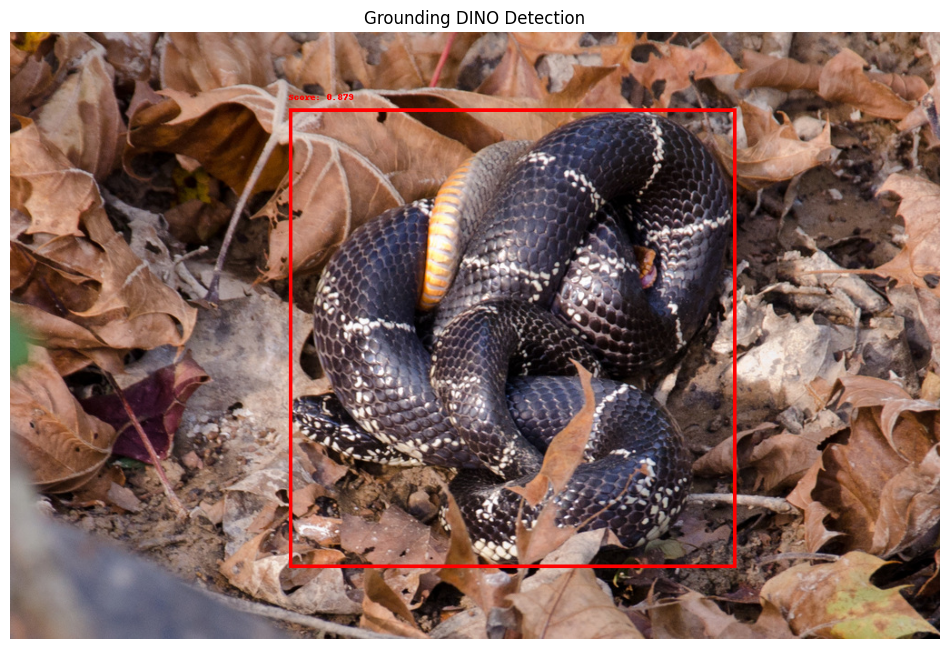

In [49]:
## Visualize the detection
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

image = Image.open(sample["image_local_path"]).convert("RGB")
annotated = image.copy()

draw = ImageDraw.Draw(annotated)

for box, score in zip(boxes, scores):
    x1, y1, x2, y2 = box.tolist()
    draw.rectangle(
        [x1, y1, x2, y2],
        outline="red",
        width=4
    )
    draw.text(
        (x1, max(0, y1 - 18)),
        f"Score: {score:.3f}",
        fill="red"
    )

plt.figure(figsize=(12, 8))
plt.imshow(annotated)
plt.axis("off")
plt.title("Grounding DINO Detection")
plt.show()


| Metric | What it measures | Why we keep it |
|---|---|---|
| `box_area_frac` | Fraction of the image occupied by the bounding box | Identifies very small or large candidate regions |
| `aspect_ratio` | Bounding-box width divided by height | Describes the shape of the detected region |
| `edge_proximity_frac` | Normalized distance from the nearest image boundary | Flags possible boundary truncation |
| `center_offset_frac` | Normalized distance between the box center and image center | Describes the spatial position of detections |
| `score_rank_gap` | Difference between rank-1 and rank-2 detection scores | Measures score separation between the top candidates |
| `is_valid_box` | Checks that coordinates define a valid box inside the image | Detects invalid bounding-box geometry |


In [52]:

def compute_box_metrics(
    x0, y0, x1, y1,
    img_w, img_h
):
    w = x1 - x0
    h = y1 - y0

    img_area = img_w * img_h
    box_area = w * h

    # Bounding box geometry
    box_area_frac = (
        box_area / img_area if img_area > 0 else 0.0
    )

    aspect_ratio = (
        w / h if h > 0 else 0.0
    )

    # Distance from the nearest image edge
    diagonal = (img_w**2 + img_h**2)**0.5

    min_edge_dist = min(
        x0, y0, img_w - x1, img_h - y1
    )

    edge_proximity_frac = (
        min_edge_dist / diagonal if diagonal > 0 else 0.0
    )

    # Validity check
    is_valid_box = (
        w > 0 and h > 0
        and x0 >= 0 and y0 >= 0
        and x1 <= img_w and y1 <= img_h
    )

    return {
        "box_area_frac": round(float(box_area_frac), 6),
        "aspect_ratio": round(float(aspect_ratio), 4),
        "edge_proximity_frac": round(float(edge_proximity_frac), 4),
        "is_valid_box": bool(is_valid_box),
    }


In [53]:

def build_detection_rows(
    original_row,
    boxes,
    scores,
    labels,
    img_w,
    img_h,
    prompt,
    top_n=5
):
    # Image-level statistics
    n_detections = len(boxes)

    img_stats = {
        "img_width": img_w,
        "img_height": img_h,
        "n_detections": n_detections,
        "max_score": float(scores.max()) if n_detections else None,
        "mean_score": float(scores.mean()) if n_detections else None,
        "detection_flag": n_detections > 0,
        "prompt_used": prompt,
    }

    metric_names = [
        "box_area_frac",
        "aspect_ratio",
        "edge_proximity_frac",
        "center_offset_frac",
        "score_rank_gap",
        "is_valid_box",
    ]

    # Preserve images with no detections
    if n_detections == 0:
        return [{
            **original_row,
            **img_stats,
            "rank": None,
            "score": None,
            "group": None,
            "label": None,
            "x0": None, "y0": None,
            "x1": None, "y1": None,
            **{name: None for name in metric_names},
        }]

    # Score gap between the two highest-ranked detections
    score_rank_gap = (
        float(scores[0] - scores[1])
        if n_detections >= 2 else None
    )

    group = Path(str(original_row["image_local_path"])).stem

    rows = []

    for rank in range(min(top_n, n_detections)):
        x0, y0, x1, y1 = map(float, boxes[rank])

        metrics = compute_box_metrics(
            x0, y0, x1, y1, img_w, img_h
        )

        # Spatial center offset, normalized by image diagonal
        diagonal = (img_w**2 + img_h**2)**0.5

        box_cx = (x0 + x1) / 2
        box_cy = (y0 + y1) / 2

        metrics["center_offset_frac"] = round(
            (
                (box_cx - img_w / 2)**2
                + (box_cy - img_h / 2)**2
            )**0.5 / diagonal,
            4
        ) if diagonal > 0 else None

        metrics["score_rank_gap"] = (
            round(score_rank_gap, 4)
            if score_rank_gap is not None else None
        )

        rows.append({
            **original_row,
            **img_stats,
            "rank": rank + 1,
            "score": float(scores[rank]),
            "group": group,
            "label": str(labels[rank]),
            "x0": x0,
            "y0": y0,
            "x1": x1,
            "y1": y1,
            **metrics,
        })

    return rows


In [54]:
rows = build_detection_rows(
    original_row=sample.to_dict(),
    boxes=boxes,
    scores=scores,
    labels=labels,
    img_w=img_w,
    img_h=img_h,
    prompt=str(sample["grounding_dino_prompt"]),
    top_n=5
)

df_test = pd.DataFrame(rows)

display(df_test[[
    "photo_id",
    "rank",
    "score",
    "label",
    "box_area_frac",
    "aspect_ratio",
    "edge_proximity_frac",
    "center_offset_frac",
    "score_rank_gap",
    "is_valid_box",
]])

,photo_id,rank,score,label,box_area_frac,aspect_ratio,edge_proximity_frac,center_offset_frac,score_rank_gap,is_valid_box
0,529902,1,0.878612,brown snake,0.363218,0.9728,0.0642,0.0342,None,True


# Run the GroundingDino on the whole dataset

In [60]:
all_rows = []
det_errors = []
skipped_no_file = 0
processed_ok = 0

In [61]:

for _, meta_row in tqdm(
    df_run.iterrows(),
    total=len(df_run),
    desc="Grounding DINO"
):
    image_path = str(meta_row["image_local_path"])
    prompt = str(meta_row["grounding_dino_prompt"])
    row_dict = meta_row.to_dict()

    if not Path(image_path).is_file():
        skipped_no_file += 1
        det_errors.append({
            "photo_id": meta_row["photo_id"],
            "image_path": image_path,
            "error": "file not found"
        })
        continue

    try:
        boxes, scores, labels, img_w, img_h = run_grounding_dino(
            model=gdino_model,
            image_path=image_path,
            prompt=prompt,
            box_threshold=BOX_THRESHOLD,
            text_threshold=TEXT_THRESHOLD
        )

        rows = build_detection_rows(
            original_row=row_dict,
            boxes=boxes,
            scores=scores,
            labels=labels,
            img_w=img_w,
            img_h=img_h,
            prompt=prompt,
            top_n=TOP_N
        )

        all_rows.extend(rows)
        processed_ok += 1

    except Exception as exc:
        det_errors.append({
            "photo_id": meta_row["photo_id"],
            "image_path": image_path,
            "error": str(exc)
        })
        print(f"[ERROR] {Path(image_path).name}: {exc}")


Grounding DINO: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:01<00:00,  8.80it/s]


In [62]:
print("Selected images:", len(df_run))
print("Successfully processed:", processed_ok)
print("Detection rows:", len(all_rows))
print("Missing files:", skipped_no_file)
print("Errors:", len(det_errors))

Selected images: 10
Successfully processed: 10
Detection rows: 15
Missing files: 0
Errors: 0


In [63]:
df_det = pd.DataFrame(all_rows)

print("Total output rows:", len(df_det))
print("Images with detections:",
      df_det.loc[df_det["detection_flag"], "photo_id"].nunique())

print("Images without detections:",
      df_det.loc[~df_det["detection_flag"], "photo_id"].nunique())

print("Actual bounding boxes:",
      df_det["rank"].notna().sum())

display(df_det[[
    "photo_id",
    "scientific_name",
    "rank",
    "score",
    "label",
    "box_area_frac",
    "is_valid_box"
]].head(15))

Total output rows: 15
Images with detections: 9
Images without detections: 1
Actual bounding boxes: 14


,photo_id,scientific_name,rank,score,label,box_area_frac,is_valid_box
0,421440,Geococcyx californianus,1.0,0.891475,brown bird,0.163672,True
1,421441,Geococcyx californianus,1.0,0.867635,brown bird,0.241432,True
2,421442,Geococcyx californianus,1.0,0.819098,brown bird,0.129190,True
3,421442,Geococcyx californianus,2.0,0.366803,head,0.011971,True
4,421443,Geococcyx californianus,1.0,0.880275,brown bird,0.157575,True
5,421443,Geococcyx californianus,2.0,0.386433,head,0.008197,True
6,421443,Geococcyx californianus,3.0,0.380729,long black tail,0.029533,True
7,521779,Lycophidion capense,1.0,0.448536,brown snake,0.495251,True
8,521779,Lycophidion capense,2.0,0.400622,brown snake,0.553134,True
9,28352912,Lycophidion capense,NaN,NaN,NaN,NaN,None


# Evaluation

In [64]:

df_results = pd.DataFrame(all_rows)

# Separate actual detections from placeholder rows
detected = df_results[df_results["detection_flag"] == True].copy()
no_det = df_results[df_results["detection_flag"] == False].copy()

n_images = processed_ok
n_detected = detected["image_local_path"].nunique()
n_boxes = len(detected)

detection_rate = n_detected / n_images if n_images else 0

print("=" * 55)
print("GROUNDING DINO EVALUATION SUMMARY")
print("=" * 55)

print(f"Images processed         : {n_images}")
print(f"Images with detections   : {n_detected}")
print(f"Images without detections: {len(no_det)}")
print(f"Detection rate           : {detection_rate:.2%}")
print(f"Total retained boxes     : {n_boxes}")

if n_detected > 0:
    print(f"Mean boxes per processed image: {n_boxes / n_images:.2f}")
    print(f"Mean boxes per detected image : {n_boxes / n_detected:.2f}")

if not detected.empty:
    print("\n── Detection scores ──")
    print(detected["score"].describe().round(4))

    print("\n── Bounding-box area fractions ──")
    print(detected["box_area_frac"].describe().round(4))

    print("\n── Geometry diagnostics ──")
    print(f"Boxes < 2% of image  : {(detected['box_area_frac'] < 0.02).sum()}")
    print(f"Boxes > 70% of image : {(detected['box_area_frac'] > 0.70).sum()}")
    print(f"Boxes near edge     : {(detected['edge_proximity_frac'] < 0.01).sum()}")
    print(f"Valid boxes         : {detected['is_valid_box'].sum()} / {n_boxes}")

print("\n── Detection counts per image ──")
print(
    df_results.groupby("image_local_path")["rank"]
    .count()
    .value_counts()
    .sort_index()
)


GROUNDING DINO EVALUATION SUMMARY
Images processed         : 10
Images with detections   : 9
Images without detections: 1
Detection rate           : 90.00%
Total retained boxes     : 14
Mean boxes per processed image: 1.40
Mean boxes per detected image : 1.56

── Detection scores ──
count    14.0000
mean      0.5790
std       0.2288
min       0.3668
25%       0.3874
50%       0.4483
75%       0.8555
max       0.8915
Name: score, dtype: float64

── Bounding-box area fractions ──
count    14.0000
mean      0.2637
std       0.1913
min       0.0082
25%       0.1363
50%       0.2635
75%       0.3671
max       0.5649
Name: box_area_frac, dtype: float64

── Geometry diagnostics ──
Boxes < 2% of image  : 2
Boxes > 70% of image : 0
Boxes near edge     : 5
Valid boxes         : 14 / 14

── Detection counts per image ──
rank
0    1
1    5
2    3
3    1
Name: count, dtype: int64


# Save the results

In [65]:

# Convert results to DataFrames
df_results = pd.DataFrame(all_rows)
df_errors = pd.DataFrame(det_errors)


In [72]:
# Save detection results
df_results.to_csv(PILOT_PATH, index=False)

# Save errors, even if there are none
df_errors.to_csv(ERROR_PATH, index=False)

print("Saved detection results:", PILOT_PATH)
print("Saved error log:", ERROR_PATH)
print("Detection records:", len(df_results))


Saved detection results: /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/object_detection/output/grounding_dino_pilot_detections.csv
Saved error log: /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/object_detection/output/errors/grounding_dino_pilot_errors.csv
Detection records: 15
